# Validade Temporal e Supersessão de Fatos em Memória Associativa Hebbiana para Agentes LLM
## Notebook 01 — Reprodução da Baseline (HeLa-Mem, ACL 2026)

---

* **Autor:** Filipe Augusto de Ataíde Barbosa (`faab@cin.ufpe.br`)
* **Instituição:** Centro de Informática (CIn) — Universidade Federal de Pernambuco (UFPE)
* **Disciplina:** Aprendizado Profundo / Deep Learning
* **Artigo-Base:** *HeLa-Mem: Hebbian Learning and Associative Memory for LLM Agents* (ACL 2026)
* **Repositório Oficial:** [`https://github.com/ReinerBRO/HeLa-Mem`](https://github.com/ReinerBRO/HeLa-Mem) (commit fixado: `68f19b3`)
* **Dados:** arquivo `data/longmemeval_s.json` distribuído com o HeLa-Mem (500 questões do *LongMemEval*, ICLR 2025). Como mostra a Seção 4, esse arquivo contém **apenas as sessões de evidência** de cada questão (equivalente à variante *oracle*), e não as ~40 sessões do *LongMemEval-S* oficial.

---

### Objetivos deste Notebook

1. **Reprodução sem modificar o código:** cumprir a primeira diretriz da disciplina, executando o código oficial do HeLa-Mem sem alterações. O código está intacto (Seção 3), mas dois hiperparâmetros ficaram com os valores padrão do código Python em vez dos valores dos scripts oficiais (Seção 6).
2. **Apresentação da arquitetura:** memória episódica, memória semântica e ativação espalhada, conforme implementadas no código.
3. **Inspeção do benchmark** e de sua estrutura real.
4. **Execução controlada (piloto)** com a configuração dos scripts oficiais.
5. **Análise dos resultados da reprodução completa (500 questões)** frente ao valor reportado no artigo.
6. **Diagnóstico de falhas por categoria**, usando taxas de erro.
7. **Estudo de caso e visualização do grafo** gerado na reprodução.

> Para a proposta, a ablação B0 e a análise estatística, veja o **Notebook 02**. A auditoria do processo está em `reports/analysis/R05_auditoria_processo_20261104.md`.

## 1. Fundamentação: Arquitetura do HeLa-Mem (como implementada)

O **HeLa-Mem** organiza a memória de longo prazo de um agente como um grafo com **plasticidade hebbiana** (*"neurons that fire together, wire together"*): memórias recuperadas juntas passam a se ativar mutuamente.

### Componentes (referências ao código em `external/HeLa-Mem/hela_mem/`)

1. **Memória Episódica (`HebbianMemoryGraph`, `hebbian_memory.py`):**
   * Cada nó é um trecho de diálogo com embedding e palavras-chave extraídas por LLM.
   * Nós consecutivos são ligados com peso 0,5 (`add_memory`).
   * Quando um conjunto de nós é recuperado junto, cada par recebe um incremento constante (`reinforce_memory_cluster`):
     $$w_{ij} \leftarrow \min(1,\; w_{ij} + \eta), \quad \eta = 0{,}02$$

2. **Memória Semântica (`HebbianKnowledgeMemory`, `hebbian_knowledge_memory.py`):**
   * Um LLM extrai fatos do usuário a cada 10 turnos (`encode_longmemeval.py`); cada fato vira um nó com metadado `{"type": "fact"}`.
   * O fato recebe o horário de execução do script (`get_timestamp()`), não a data da sessão de origem.

3. **Recuperação com ativação espalhada (`retrieve`):**
   * Score base de cada nó: similaridade de cosseno reescalada para $[0,1]$ mais um bônus de palavras-chave, multiplicado por um fator de decaimento temporal:
     $$s_i = \gamma_i \cdot \left( \tfrac{1 + \cos(\mathbf{e}_i, \mathbf{e}_Q)}{2} + \kappa \cdot \text{KW}_i \right)$$
   * Nós com $s_i$ acima de um limiar espalham ativação aos vizinhos: $\text{Spread}_j = \sum_i \alpha \, s_i \, w_{ij}$.
   * O resultado combina os *top-k* por $s_i$ com até `MAX_FLIPPED` nós que entram no ranking graças ao espalhamento.

> **Limitações observadas no código:**
> * O fator $\gamma_i = e^{-\Delta t/\tau}$ deveria decair com o tempo de relógio, mas a chamada `compute_time_decay(node["timestamp"], current_time)` passa uma data no lugar de $\tau$ e cai no ramo de exceção. **Na prática, $\gamma_i = 1$** (não há decaimento).
> * Não existe noção de **validade** de um fato: quando um atributo do usuário muda, o fato antigo e o novo coexistem e competem só por similaridade. Essa é a lacuna explorada pela proposta (Notebook 02).

## 2. Configuração do Ambiente e Verificação de Dependências

In [1]:
import os
import sys
import json
import time
from pathlib import Path
from datetime import datetime

# Garante suporte a UTF-8 no Windows
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")

# Definição das pastas raiz do projeto
NOTEBOOK_DIR = Path.cwd()
ROOT_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
HELA_DIR = ROOT_DIR / "external" / "HeLa-Mem"
RESULTS_DIR = ROOT_DIR / "results" / "longmemeval_baseline_full"
DATA_PATH = HELA_DIR / "data" / "longmemeval_s.json"

for label, p in [("Pasta HeLa-Mem", HELA_DIR), ("Dados (longmemeval_s.json)", DATA_PATH), ("Resultados da reprodução", RESULTS_DIR)]:
    print(f"{label}: {p.relative_to(ROOT_DIR)} (existe: {p.exists()})")

# Carrega credenciais a partir do arquivo .env
from dotenv import load_dotenv
env_loaded = load_dotenv(ROOT_DIR / ".env")
api_key = os.environ.get("OPENAI_API_KEY")
print(f"\n.env carregado: {env_loaded}")
print(f"OPENAI_API_KEY configurada: {'Sim' if api_key else 'Não (necessária apenas para o piloto ao vivo)'}")

# Importações para análise e visualização de dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

# Estilo gráfico elegante
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

print("\nAmbiente configurado com sucesso!")

Pasta HeLa-Mem: external\HeLa-Mem (existe: True)
Dados (longmemeval_s.json): external\HeLa-Mem\data\longmemeval_s.json (existe: True)
Resultados da reprodução: results\longmemeval_baseline_full (existe: True)

.env carregado: False
OPENAI_API_KEY configurada: Não (necessária apenas para o piloto ao vivo)



Ambiente configurado com sucesso!


## 3. Integridade do Código-Base Original

Verificamos o commit do submódulo `external/HeLa-Mem` e se há alterações locais. Nenhuma linha do código oficial foi alterada na reprodução. A configuração de execução (hiperparâmetros) é verificada separadamente na Seção 6.

In [2]:
import subprocess

try:
    commit_hash = subprocess.check_output(
        ["git", "-C", str(HELA_DIR), "rev-parse", "HEAD"],
        text=True
    ).strip()
    status = subprocess.check_output(
        ["git", "-C", str(HELA_DIR), "status", "--porcelain"],
        text=True
    ).strip()
    print(f"Commit do repositório oficial HeLa-Mem: {commit_hash}")
    print(f"Modificações no submódulo HeLa-Mem: {'NENHUMA (código 100% original)' if not status else 'Modificações detectadas'}")
except Exception as e:
    print(f"Aviso ao consultar git: {e}")

# Adicionar external/HeLa-Mem ao sys.path para importação direta
if str(HELA_DIR) not in sys.path:
    sys.path.insert(0, str(HELA_DIR))

# Importação dos módulos originais da baseline (sem modificações)
from hela_mem.encode_longmemeval import encode_longmemeval
from hela_mem.eval_longmemeval import eval_longmemeval
from hela_mem.hebbian_memory import HebbianMemoryGraph
from hela_mem.hebbian_knowledge_memory import HebbianKnowledgeMemory
from hela_mem.hebbian_retriever import HebbianRetriever

print("\nMódulos oficiais do HeLa-Mem importados com sucesso diretamente de external/HeLa-Mem/hela_mem/!")

Commit do repositório oficial HeLa-Mem: 68f19b3fac8c6156570d5aeb3a7a3e8f3ba7cb04
Modificações no submódulo HeLa-Mem: NENHUMA (código 100% original)



Módulos oficiais do HeLa-Mem importados com sucesso diretamente de external/HeLa-Mem/hela_mem/!


## 4. Exploração do Benchmark

O arquivo `data/longmemeval_s.json` distribuído com o HeLa-Mem contém as **500 questões** do *LongMemEval* (ICLR 2025), em 6 categorias. Abaixo verificamos também **quantas sessões de histórico** cada questão tem e se elas coincidem com as sessões de evidência (`answer_session_ids`).

In [3]:
with open(DATA_PATH, "r", encoding="utf-8") as f:
    dataset = json.load(f)

print(f"Total de questões no arquivo: {len(dataset)}")

# Mapeamento de categorias cognitivas
categories = [item.get("question_type") for item in dataset]
cat_series = pd.Series(categories).value_counts()
cat_df = pd.DataFrame({"Categoria": cat_series.index, "Total de Amostras": cat_series.values, "Percentual (%)": (cat_series.values / len(dataset) * 100).round(2)})
display(cat_df)

# Exibição de uma amostra detalhada do dataset
sample = dataset[0]
print("\n" + "="*70)
print(f"EXEMPLO DE INSTÂNCIA: ID {sample['question_id']} ({sample['question_type']})")
print("="*70)
print(f"Pergunta: {sample['question']}")
print(f"Ground Truth (Resposta Esperada): {sample['answer']}")
print(f"Data da Pergunta (question_date): {sample.get('question_date', 'N/A')}")
print(f"Datas das Sessões (haystack_dates): {sample.get('haystack_dates', [])}")
print(f"Número de Sessões no Diálogo: {len(sample.get('haystack_sessions', []))}")
print("-" * 70)
first_session = sample['haystack_sessions'][0]
if isinstance(first_session, list) and len(first_session) > 0 and isinstance(first_session[0], dict):
    first_turn = first_session[0]
    print(f"Primeiro turno da 1ª sessão [{first_turn.get('role')}]: {first_turn.get('content', '')[:160]}...")
elif isinstance(first_session, str):
    print(f"Primeiros 200 caracteres da 1ª sessão:\n{first_session[:200]}...")

Total de questões no arquivo: 500


,Categoria,Total de Amostras,Percentual (%)
0,temporal-reasoning,133,26.6
1,multi-session,133,26.6
2,knowledge-update,78,15.6
3,single-session-user,70,14.0
4,single-session-assistant,56,11.2
5,single-session-preference,30,6.0



EXEMPLO DE INSTÂNCIA: ID gpt4_2655b836 (temporal-reasoning)
Pergunta: What was the first issue I had with my new car after its first service?
Ground Truth (Resposta Esperada): GPS system not functioning correctly
Data da Pergunta (question_date): 2023/04/10 (Mon) 23:07
Datas das Sessões (haystack_dates): ['2023/04/10 (Mon) 17:50', '2023/04/10 (Mon) 14:47', '2023/04/10 (Mon) 17:15']
Número de Sessões no Diálogo: 3
----------------------------------------------------------------------
Primeiro turno da 1ª sessão [user]: I'm thinking of getting my car detailed soon. Do you know any good detailers in the area or have any recommendations? By the way, I just got my car serviced for...


In [4]:
# Estrutura real do histórico: sessões por questão e comparação com as sessões de evidência
sess_df = pd.DataFrame([{
    "question_type": it["question_type"],
    "n_sessoes": len(it["haystack_sessions"]),
    "so_evidencia": set(it.get("haystack_session_ids", [])) == set(it.get("answer_session_ids", [])),
} for it in dataset])

display(sess_df.groupby("question_type").agg(
    questoes=("n_sessoes", "size"),
    sessoes_media=("n_sessoes", "mean"),
    sessoes_max=("n_sessoes", "max"),
    so_evidencia=("so_evidencia", "mean"),
).round(2))

print(f"Questões cujo histórico contém APENAS as sessões de evidência: {sess_df['so_evidencia'].sum()} de {len(sess_df)}")
print("O LongMemEval-S oficial tem ~40 sessões por questão (~115 mil tokens), incluindo sessões de distração.")
print("Este arquivo corresponde, portanto, à variante 'oracle': não testa encontrar o fato em meio a ruído.")

,questoes,sessoes_media,sessoes_max,so_evidencia
question_type,,,,
knowledge-update,78,2.00,2,1.0
multi-session,133,2.59,5,1.0
single-session-assistant,56,1.00,1,1.0
single-session-preference,30,1.00,1,1.0
single-session-user,70,1.00,1,1.0
temporal-reasoning,133,2.20,6,1.0


Questões cujo histórico contém APENAS as sessões de evidência: 500 de 500
O LongMemEval-S oficial tem ~40 sessões por questão (~115 mil tokens), incluindo sessões de distração.
Este arquivo corresponde, portanto, à variante 'oracle': não testa encontrar o fato em meio a ruído.


## 5. Execução Controlada da Baseline (Modo Amostra / Piloto)

Abaixo está o pipeline oficial de execução em Python. Ele utiliza as funções `encode_longmemeval` (para extração de fatos e montagem dos grafos hebbianos) e `eval_longmemeval` (para busca no grafo e geração da resposta com juiz LLM).

> **Nota Operacional:** Avaliar todos os 500 itens realiza mais de 10.000 chamadas à API da OpenAI e requer cerca de 2 horas. Para fins de verificação interativa neste notebook, a flag `RUN_LIVE_PILOT` vem definida como `False`. Se desejar testar a chamada ao vivo em 1 item piloto, altere para `True`.

In [5]:
import os as _os

RUN_LIVE_PILOT = False  # Altere para True para rodar 1 questão ao vivo (requer OPENAI_API_KEY)
PILOT_OUTPUT_DIR = ROOT_DIR / "results" / "longmemeval_notebook_demo"

# Configuração dos scripts oficiais (scripts/encode_longmemeval.sh e scripts/eval_longmemeval.sh).
# A reprodução completa de 500 itens NÃO usou estes valores para MAX_FLIPPED e KEYWORD_WEIGHT (ver Seção 6).
OFFICIAL_ENV = {
    "HEBBIAN_MODEL": "gpt-4o-mini",
    "HEBBIAN_TAU": "1e7",
    "HEBBIAN_LEARNING_RATE": "0.02",
    "HEBBIAN_DECAY_RATE": "0.995",
    "HEBBIAN_ACTIVATION_ALPHA": "0.1",
    "HEBBIAN_SPREADING_THRESHOLD": "0.4",
    "HEBBIAN_MAX_FLIPPED": "3",
    "HEBBIAN_KEYWORD_WEIGHT": "0.7",
    "HEBBIAN_KNOWLEDGE_BUFFER_SIZE": "10",
}

if RUN_LIVE_PILOT:
    if not api_key:
        print("ERRO: OPENAI_API_KEY necessária para execução ao vivo.")
    else:
        _os.environ.update(OFFICIAL_ENV)
        print("Executando pipeline original HeLa-Mem para 1 item piloto (config. dos scripts oficiais)...")
        PILOT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        # workers=1 evita a condição de corrida no carregamento do modelo de embeddings
        encode_longmemeval(data_path=str(DATA_PATH), output_dir=str(PILOT_OUTPUT_DIR),
                           num_items=1, start_item=0, workers=1, skip_knowledge=False)
        eval_longmemeval(data_path=str(DATA_PATH), mem_dir=str(PILOT_OUTPUT_DIR),
                         num_items=1, start_item=0, top_k=15, semantic_top_k=5,
                         use_consolidation=False, workers=1)
        print("\nExecução piloto concluída.")
else:
    print("Modo piloto ao vivo desativado (RUN_LIVE_PILOT=False).")
    print("A análise a seguir usa os resultados versionados da reprodução completa (500 itens).")

Modo piloto ao vivo desativado (RUN_LIVE_PILOT=False).
A análise a seguir usa os resultados versionados da reprodução completa (500 itens).


## 6. Resultados da Reprodução Completa (500 Itens)

Carregamos o `eval_summary.json` gerado na execução completa e conferimos os hiperparâmetros registrados contra os scripts oficiais.

In [6]:
SUMMARY_PATH = RESULTS_DIR / "eval_results" / "eval_summary.json"

with open(SUMMARY_PATH, "r", encoding="utf-8") as f:
    eval_summary = json.load(f)

print("=" * 70)
print("METADADOS DA REPLICAÇÃO EMPÍRICA CONGELADA")
print("=" * 70)
print(f"Timestamp de Conclusão: {eval_summary['timestamp']}")
print(f"Total de Itens Avaliados: {eval_summary['total_items']}")
print(f"Total de Acertos: {eval_summary['total_correct']}")
print(f"Acurácia Global Obtida: {eval_summary['overall_accuracy']:.2f}%")
print(f"Hiperparâmetros Hebbianos: top_k={eval_summary['params']['top_k']}, alpha={eval_summary['params']['activation_alpha']}, eta={eval_summary['params']['learning_rate']}")

METADADOS DA REPLICAÇÃO EMPÍRICA CONGELADA
Timestamp de Conclusão: 2026-09-29T19:45:02.342738
Total de Itens Avaliados: 500
Total de Acertos: 306
Acurácia Global Obtida: 61.20%
Hiperparâmetros Hebbianos: top_k=15, alpha=0.1, eta=0.02


In [7]:
# Hiperparâmetros registrados na execução vs. scripts oficiais
official = {"max_flipped": "3", "keyword_weight": "0.7", "learning_rate": "0.02", "activation_alpha": "0.1",
            "spreading_threshold": "0.4", "decay_rate": "0.995", "tau": "1e7", "top_k": "15", "semantic_top_k": "5"}
params = eval_summary["params"]
param_df = pd.DataFrame([{
    "Parâmetro": k,
    "Script oficial": v,
    "Reprodução": str(params.get(k)),
    "Igual?": float(v) == float(params.get(k)),
} for k, v in official.items()])
display(param_df)
print("Divergências: MAX_FLIPPED e KEYWORD_WEIGHT ficaram com os valores padrão do código Python (5 e 0,5),")
print("porque o módulo foi chamado diretamente, sem os scripts .sh. Isso afeta a comparação com o artigo,")
print("mas não a comparação A vs. B, pois B reutiliza os grafos episódicos e o ambiente de A.")

,Parâmetro,Script oficial,Reprodução,Igual?
0,max_flipped,3,5,False
1,keyword_weight,0.7,0.5,False
2,learning_rate,0.02,0.02,True
3,activation_alpha,0.1,0.1,True
4,spreading_threshold,0.4,0.4,True
5,decay_rate,0.995,0.995,True
6,tau,1e7,1e7,True
7,top_k,15,15,True
8,semantic_top_k,5,5,True


Divergências: MAX_FLIPPED e KEYWORD_WEIGHT ficaram com os valores padrão do código Python (5 e 0,5),
porque o módulo foi chamado diretamente, sem os scripts .sh. Isso afeta a comparação com o artigo,
mas não a comparação A vs. B, pois B reutiliza os grafos episódicos e o ambiente de A.


### Comparação com o Valor Reportado no Artigo

O artigo reporta as categorias de sessão única **agregadas** (78,85%). Por isso a comparação é feita contra o agregado das três categorias de sessão única, e não contra `single-session-user` isoladamente.

In [8]:
# Valores reportados no artigo (ACL 2026)
paper = {"OVERALL": 65.40, "temporal-reasoning": 50.38, "multi-session": 57.14,
         "knowledge-update": 78.21, "single-session (agregado)": 78.85}

per_type = eval_summary["per_type"]
ss_types = ["single-session-user", "single-session-assistant", "single-session-preference"]
ss_correct = sum(per_type[t]["correct"] for t in ss_types)
ss_total = sum(per_type[t]["total"] for t in ss_types)

rows = [("OVERALL", eval_summary["total_correct"], eval_summary["total_items"])]
rows += [(t, per_type[t]["correct"], per_type[t]["total"]) for t in ["temporal-reasoning", "multi-session", "knowledge-update"]]
rows += [("single-session (agregado)", ss_correct, ss_total)]

comparison_df = pd.DataFrame([{
    "Categoria": name,
    "Acertos": f"{corr}/{tot}",
    "Reprodução (%)": round(100 * corr / tot, 2),
    "Artigo (%)": paper[name],
    "Diferença (p.p.)": round(100 * corr / tot - paper[name], 2),
} for name, corr, tot in rows])
display(comparison_df)

print("Detalhe das categorias de sessão única (o artigo não as reporta separadamente):")
display(pd.DataFrame([{"Categoria": t, "Acertos": f"{per_type[t]['correct']}/{per_type[t]['total']}",
                       "Reprodução (%)": round(per_type[t]['accuracy'], 2)} for t in ss_types]))

,Categoria,Acertos,Reprodução (%),Artigo (%),Diferença (p.p.)
0,OVERALL,306/500,61.20,65.40,-4.20
1,temporal-reasoning,69/133,51.88,50.38,1.50
2,multi-session,62/133,46.62,57.14,-10.52
3,knowledge-update,57/78,73.08,78.21,-5.13
4,single-session (agregado),118/156,75.64,78.85,-3.21


Detalhe das categorias de sessão única (o artigo não as reporta separadamente):


,Categoria,Acertos,Reprodução (%)
0,single-session-user,61/70,87.14
1,single-session-assistant,49/56,87.50
2,single-session-preference,8/30,26.67


## 7. Visualização: Reprodução vs. Artigo

A reprodução fica 4,2 p.p. abaixo do artigo no total. Os desvios de hiperparâmetros (Seção 6) e a possível falha na extração semântica (360/500 grafos semânticos vazios; ver R05) são explicações candidatas, ainda não testadas.

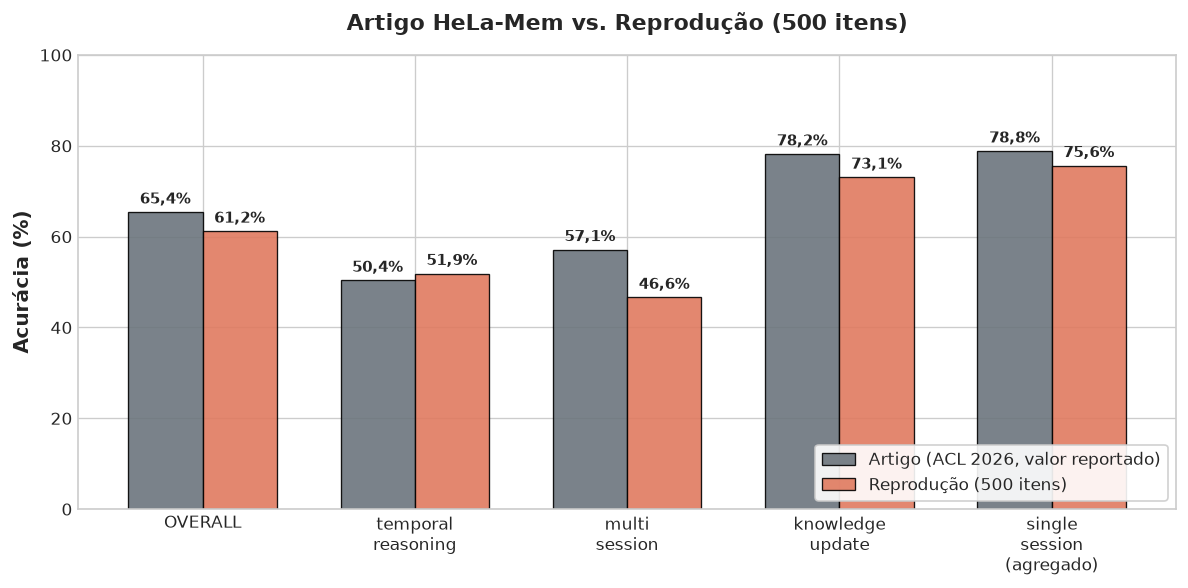

In [9]:
labels = list(comparison_df["Categoria"])
paper_vals = list(comparison_df["Artigo (%)"])
reprod_vals = list(comparison_df["Reprodução (%)"])

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width/2, paper_vals, width, label='Artigo (ACL 2026, valor reportado)', color='#6c757d', alpha=0.9, edgecolor='black', linewidth=0.8)
rects2 = ax.bar(x + width/2, reprod_vals, width, label='Reprodução (500 itens)', color='#e07a5f', alpha=0.9, edgecolor='black', linewidth=0.8)

ax.set_ylabel('Acurácia (%)', fontsize=12, fontweight='bold')
ax.set_title('Artigo HeLa-Mem vs. Reprodução (500 itens)', fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels([l.replace("-", "\n").replace(" (", "\n(") for l in labels], fontsize=10)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, loc='lower right')
ax.set_ylim(0, 100)

for rects in (rects1, rects2):
    for rect in rects:
        h = rect.get_height()
        ax.annotate(f'{h:.1f}%'.replace('.', ','), xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                    textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Diagnóstico de Falhas por Categoria

A reprodução teve **306 acertos e 194 erros** (taxa de erro global de 38,80%). Para saber onde o sistema falha **mais do que o esperado**, comparamos a fração de erros de cada categoria com a fração de questões que ela representa, e olhamos a taxa de erro dentro de cada categoria.

In [10]:
results_list = eval_summary["results"]
error_items = [r for r in results_list if r.get("correct") == 0]
n_by_type = pd.Series([r["question_type"] for r in results_list]).value_counts()
err_by_type = pd.Series([r["question_type"] for r in error_items]).value_counts()

diag_df = pd.DataFrame({
    "Questões": n_by_type,
    "Erros": err_by_type,
}).fillna(0).astype(int)
diag_df["% das questões"] = (100 * diag_df["Questões"] / len(results_list)).round(1)
diag_df["% dos erros"] = (100 * diag_df["Erros"] / len(error_items)).round(1)
diag_df["Taxa de erro (%)"] = (100 * diag_df["Erros"] / diag_df["Questões"]).round(1)
diag_df = diag_df.sort_values("Taxa de erro (%)", ascending=False)
display(diag_df)

overall_err = 100 * len(error_items) / len(results_list)
print(f"Taxa de erro global: {overall_err:.1f}%")

tr_ku = ["temporal-reasoning", "knowledge-update"]
share_q = diag_df.loc[tr_ku, "Questões"].sum() / len(results_list) * 100
share_e = diag_df.loc[tr_ku, "Erros"].sum() / len(error_items) * 100
print(f"\nTR + KU: {share_q:.1f}% das questões e {share_e:.1f}% dos erros.")
print("A fatia de erros é praticamente igual à fatia de questões: não há concentração de erros nessas categorias.")
print("Knowledge Update tem taxa de erro ABAIXO da média; as maiores taxas estão em preference e multi-session.")

# Questões de abstenção: aquelas em que a resposta correta é dizer que não há informação (IDs com '_abs')
abst = [r for r in results_list if r.get("is_abstention")]
abst_wrong = [r for r in abst if r["correct"] == 0]
print(f"\nQuestões de abstenção: {len(abst)}; o modelo deixou de se abster corretamente em {len(abst_wrong)} delas.")

,Questões,Erros,% das questões,% dos erros,Taxa de erro (%)
single-session-preference,30,22,6.0,11.3,73.3
multi-session,133,71,26.6,36.6,53.4
temporal-reasoning,133,64,26.6,33.0,48.1
knowledge-update,78,21,15.6,10.8,26.9
single-session-user,70,9,14.0,4.6,12.9
single-session-assistant,56,7,11.2,3.6,12.5


Taxa de erro global: 38.8%

TR + KU: 42.2% das questões e 43.8% dos erros.
A fatia de erros é praticamente igual à fatia de questões: não há concentração de erros nessas categorias.
Knowledge Update tem taxa de erro ABAIXO da média; as maiores taxas estão em preference e multi-session.

Questões de abstenção: 29; o modelo deixou de se abster corretamente em 18 delas.


### Taxa de Erro por Categoria

O gráfico compara a taxa de erro de cada categoria com a taxa global (linha tracejada).

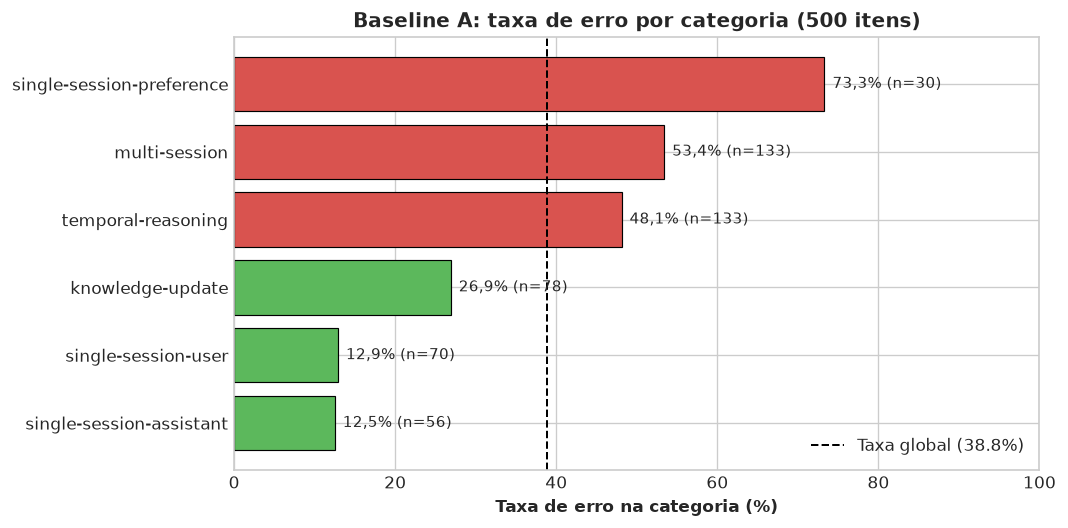

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
cats = diag_df.index.tolist()
vals = diag_df["Taxa de erro (%)"].tolist()
colors = ['#d9534f' if v > overall_err else '#5cb85c' for v in vals]
bars = ax.barh(cats, vals, color=colors, edgecolor='black', linewidth=0.7)
ax.axvline(overall_err, color='black', linestyle='--', linewidth=1.2, label=f'Taxa global ({overall_err:.1f}%)')
for bar, v, n in zip(bars, vals, diag_df["Questões"]):
    ax.text(v + 1, bar.get_y() + bar.get_height()/2, f"{v:.1f}% (n={n})".replace('.', ','), va='center', fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Taxa de erro na categoria (%)', fontweight='bold')
ax.set_title('Baseline A: taxa de erro por categoria (500 itens)', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 9. Estudo de Caso Qualitativo: Falta de Supersessão

Instâncias **`07741c44` / `07741c45`** (`knowledge-update`): o usuário guardava os tênis velhos debaixo da cama (20/mai/2023) e depois passou a guardá-los numa sapateira no armário (26/mai/2023).

* `07741c44` pergunta onde ele guardava **inicialmente**; `07741c45`, onde guarda **atualmente**.
* Como a baseline não modela a validade dos fatos, os trechos das duas sessões coexistem na memória e competem só por similaridade.

In [12]:
import re

case_id = "07741c45"
graph_case_file = RESULTS_DIR / f"{case_id}_hebbian.json"

case_item = next((item for item in dataset if item["question_id"] == case_id), None)
case_eval = next((r for r in results_list if r["question_id"] == case_id), None)

print("=" * 70)
print(f"ESTUDO DE CASO: ID {case_id} (knowledge-update)")
print("=" * 70)
print(f"Pergunta: {case_item['question']}")
print(f"Resposta correta: {case_item['answer']}")
print(f"Data da pergunta: {case_item.get('question_date')}")
print(f"Resposta da baseline: {case_eval['generated_answer']}  ->  {'ACERTOU' if case_eval['correct'] else 'ERROU (estado antigo)'}")

if graph_case_file.exists():
    with open(graph_case_file, "r", encoding="utf-8") as f:
        nodes_dict = json.load(f).get("nodes", {})
    print(f"\nNós na memória episódica desta questão: {len(nodes_dict)}")
    print("\nFrases sobre os tênis em cada nó (com a data da sessão):")
    for nid, node in nodes_dict.items():
        sentences = re.split(r"(?<=[.!?])\s+", node.get("content", ""))
        hits = [s.strip() for s in sentences if "sneaker" in s.lower() and s.lower().startswith("user")]
        hits = hits or [s.strip() for s in sentences if "under my bed" in s.lower() or "shoe rack" in s.lower()]
        for s in hits[:1]:
            print(f"  [nó {nid} | {node.get('timestamp')}] {s[:150]}")
    print("\nOs dois estados (cama e sapateira) estão na memória sem qualquer marcação de qual é o vigente;")
    print("a baseline respondeu com o estado antigo. A memória semântica de A não foi versionada,")
    print("por isso não é possível inspecionar aqui quais fatos ela recuperou.")
else:
    print(f"Grafo {graph_case_file} não encontrado. Descompacte results/baseline_episodic_500.zip.")

ESTUDO DE CASO: ID 07741c45 (knowledge-update)
Pergunta: Where do I currently keep my old sneakers?
Resposta correta: in a shoe rack in my closet
Data da pergunta: 2023/06/07 (Wed) 04:15
Resposta da baseline: under my bed  ->  ERROU (estado antigo)

Nós na memória episódica desta questão: 12

Frases sobre os tênis em cada nó (com a data da sessão):
  [nó 1 | 2023/05/20 (Sat) 12:36] By the way, I need to take care of my old sneakers, I've been keeping them under my bed for storage, and they're starting to smell.
  [nó 5 | 2023/05/20 (Sat) 12:36] User: I'm thinking of organizing my closet by type, so all my boots are together, all my sneakers are together, and so on.
  [nó 6 | 2023/05/26 (Fri) 13:05] By the way, I need to organize my closet this weekend, and I'm looking forward to get rid of some of my old sneakers in a shoe rack in it, they're cur
  [nó 8 | 2023/05/26 (Fri) 13:05] You can place them near your sneakers or inside the shoe rack.
  [nó 11 | 2023/05/26 (Fri) 13:05] By the wa

## 10. Visualização Topológica do Grafo de Memória Hebbiana

Grafo episódico de uma instância (`001be529`) gerado na reprodução. A espessura das arestas é proporcional ao peso sináptico $w_{ij}$.

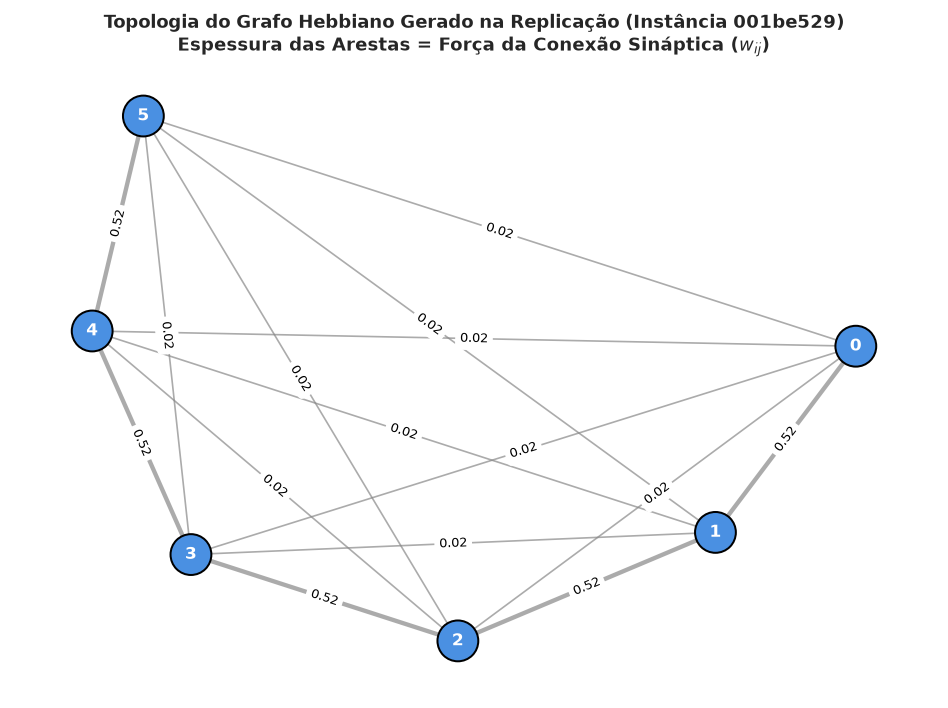

In [13]:
sample_graph_file = RESULTS_DIR / "001be529_hebbian.json"

if sample_graph_file.exists():
    with open(sample_graph_file, "r", encoding="utf-8") as f:
        gdata = json.load(f)
        
    G = nx.Graph()
    nodes_info = gdata.get("nodes", {})
    edges_info = gdata.get("edges", {})
    
    # Adicionar nós
    for nid, nprops in nodes_info.items():
        G.add_node(nid, role=nprops.get("role", "memory"), timestamp=nprops.get("timestamp", "N/A"))
        
    # Adicionar arestas ponderadas
    for u, targets in edges_info.items():
        for v, weight in targets.items():
            if weight > 0 and u in nodes_info and v in nodes_info:
                G.add_edge(u, v, weight=float(weight))
                
    fig, ax = plt.subplots(figsize=(8, 6))
    pos = nx.spring_layout(G, seed=42)
    
    # Cores dos nós
    node_colors = ['#4a90e2' for _ in G.nodes()]  # todos os nós episódicos têm role='interaction'
    
    # Espessura das arestas proporcional ao peso hebbiano
    edge_weights = [G[u][v]['weight'] for u, v in G.edges()]
    widths = [max(1.0, w * 5.0) for w in edge_weights]
    
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=600, edgecolors='black', linewidths=1.2)
    nx.draw_networkx_edges(G, pos, ax=ax, width=widths, edge_color='#888888', alpha=0.7)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=10, font_weight='bold', font_color='white')
    
    # Rótulo dos pesos das arestas
    edge_labels = {(u, v): f"{d['weight']:.2f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, ax=ax)
    
    ax.set_title("Topologia do Grafo Hebbiano Gerado na Replicação (Instância 001be529)\nEspessura das Arestas = Força da Conexão Sináptica ($w_{ij}$)", fontsize=11, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print("Arquivo de grafo de exemplo não encontrado.")

## 11. Conclusões da Reprodução

1. **Código intacto, configuração parcialmente diferente:** a baseline foi executada sobre as 500 questões com o código oficial sem alterações (commit `68f19b3`), obtendo **61,20%** de acurácia global, 4,2 p.p. abaixo do artigo (65,40%). Dois hiperparâmetros ficaram com os valores padrão do código Python (`MAX_FLIPPED`=5, `KEYWORD_WEIGHT`=0,5) em vez dos valores dos scripts oficiais (3 e 0,7).
2. **Dados:** o arquivo usado contém apenas as sessões de evidência de cada questão (variante *oracle*); é preciso confirmar se o artigo usou o mesmo arquivo antes de comparar os números diretamente.
3. **Onde a baseline erra:** as maiores taxas de erro estão em *preference* (73%) e *multi-session* (53%). *Knowledge Update* erra menos que a média (27%), e TR+KU respondem por uma fração dos erros (43,8%) igual à fração de questões que representam (42,2%). A motivação para a proposta vem dos **casos de atualização** como `07741c45`, em que o estado antigo é recuperado, e não de uma concentração estatística de erros.
4. **Limitações do código:** os fatos semânticos não têm data de validade (recebem o horário de execução) e o decaimento temporal está neutralizado por um erro de chamada; o fato antigo e o atual competem só por similaridade.
5. **Pontos em aberto:** 360 dos 500 grafos semânticos ficaram vazios na reprodução; a causa (comportamento do código ou falha de execução) está em investigação (R05, Achado 2).

---

### Ponte para a Proposta (Notebook 02)

A proposta adiciona à memória semântica **janelas de validade** $[t_{start}, t_{end}]$ ancoradas na data da sessão, **supersessão** não-destrutiva entre fatos (com arestas bidirecionais de peso 0,8) e **pertinência temporal** $\mathcal{V}(f_i, t_{query})$ na busca:

$$\mathcal{V}(f_i, t_{query}) = \begin{cases}
1, & t_{start}^{(i)} \le t_{query} \le t_{end}^{(i)} \\
\exp\left(-\frac{t_{query} - t_{end}^{(i)}}{\tau_{decay}}\right), & t_{query} > t_{end}^{(i)} \\
0, & t_{query} < t_{start}^{(i)}
\end{cases}$$

O Notebook 02 avalia a proposta, a ablação B0 que separa o efeito da extração do efeito do mecanismo temporal, e a análise estatística.